# Detección de transacciones bancarias fraudulentas

Práctica de detección de anomalías · Máster MIAX

## 1. Integrantes del grupo

In [1]:
MIEMBROS = ['Piettro Rodrigues', 'Alonso Díaz', 'Raúl Rodríguez']
for m in MIEMBROS:
    print('-', m)

- Piettro Rodrigues
- Alonso Díaz
- Raúl Rodríguez


## 2. Resumen ejecutivo

**Problema.** Asignar un score de fraude a cada fila de `credit_card_production.csv` (113 923 transacciones). La métrica es el **AUPR** (`average_precision_score`) y mayor score = más probable fraude, según el notebook de partida.

**Datos.** El fichero de construcción tiene 170 884 filas con etiqueta (295 fraudes, 0,17 %). Producción tiene las mismas 21 variables numéricas, sin etiqueta, y una distribución prácticamente idéntica a la de construcción (diferencia de medias tipificada por variable < 0,02; ver la auditoría de la sección 3).

**Enfoque.** Aprendizaje **supervisado** con tres modelos de árboles (gradient boosting regularizado, Random Forest y Extra Trees) combinados por **media de rangos**. Los modelos no supervisados (mezcla gaussiana, Isolation Forest) se evaluaron y se descartaron porque rinden menos y no mejoran el ensemble.

**Resultado de validación** (5 folds x 1 repetición, sin fuga, semilla 42): ensemble **AUPR = 0,834**, frente a 0,375 del modelo del notebook de partida (GMM de 5 componentes sobre variables crudas), recalculado aquí con las mismas particiones. La desviación entre folds va de 0,055 a 0,069 (hay ~57 fraudes por fold), por lo que las diferencias de unas milésimas entre los modelos supervisados **no son significativas**.

**Cómo leer este notebook.** Cada decisión (variables, validación, hiperparámetros, ensemble) va con una celda que la justifica con cifras calculadas en la propia ejecución. Las cifras citadas en el texto se contrastan automáticamente con lo calculado en la celda de comprobación de la sección 9.

### Mapa del notebook

| Sección | Qué contiene |
|---|---|
| 1. Integrantes | Miembros del grupo |
| 2. Resumen ejecutivo | Problema, datos, enfoque y resultado |
| Entorno y configuración | Librerías, variables de entorno, localización de los datos y código de apoyo (plegado) |
| 3. Carga y auditoría | Forma, nulos, duplicados, desbalanceo y deriva producción vs. construcción |
| 4. Ingeniería de variables | Transformación fija de variables y su evidencia |
| 5. Validación y control de fuga | K-fold estratificado repetido, AUPR y guardrail anti-fuga |
| 6. Modelos y comparación | Candidatos, regularización del boosting, validación cruzada y baseline de partida |
| 7. Ensemble y selección | Decisión final, curva PR, análisis del fraude no detectado e importancia de variables |
| 8. Scoring de producción | Ajuste final, CSV y distribución de scores |
| 9. Traza y comprobación | Tiempos por paso y contraste de las cifras citadas |
| 10. Reflexión final | Resultados, limitaciones, riesgos y mejoras |

## Entorno y configuración

Solo se usan las librerías de `requirements.txt` (numpy, pandas, scikit-learn, pydantic, joblib, matplotlib para las figuras). Todo el código está en este notebook.

In [2]:
import os
import socket
import time
import warnings
import zipfile
from dataclasses import dataclass, field
from pathlib import Path
from contextlib import contextmanager
from typing import Callable, Iterator, Protocol, Sequence, runtime_checkable
from urllib.error import URLError
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from pydantic import BaseModel, ConfigDict, Field, model_validator
from sklearn.cluster import KMeans
from sklearn.ensemble import (
    ExtraTreesClassifier, HistGradientBoostingClassifier, IsolationForest, RandomForestClassifier,
)
from sklearn.metrics import precision_recall_curve
from sklearn.mixture import GaussianMixture

pd.options.display.max_columns = None
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
DEMO_MODE = os.environ.get("DEMO_MODE", "false").lower() == "true"
# Colab: descarga los CSV de Drive (mismas copias que el notebook de partida) si no están en disco
DESCARGAR_DATOS = os.environ.get("DESCARGAR_DATOS", "false").lower() == "true"
SEED = int(os.environ.get("SEED", "42"))
SALIDA_CSV = os.environ.get("OUTPUT_CSV", "scores.csv")
CV_REPETICIONES = int(os.environ.get("CV_REPETICIONES", "1"))  # 5 particiones por repetición; más repeticiones, más tiempo
N_JOBS = 2
# Comprobación de cifras: por defecto solo avisa (otras versiones de librerías pueden mover los decimales); en modo estricto detiene el notebook
COMPROBACION_ESTRICTA = os.environ.get("COMPROBACION_ESTRICTA", "false").lower() == "true"
TIMEOUT_DESCARGA = 120  # segundos de espera de red por operación

CARPETAS_DATOS = (".", "data", "../data")
NOMBRES_DATOS = {"construccion": "credit_card_construction.csv", "produccion": "credit_card_production.csv"}
URLS_DATOS = {
    "construccion": "https://drive.usercontent.google.com/download?id=1IyihCpU_krumRnPBvMR0ytEfzv_Z2Jg3&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280",
    "produccion": "https://drive.usercontent.google.com/download?id=1N5xRbkchTR7FLskuIEmZPYHklsRVJy_q&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280",
}


def descargar_zip(url: str, destino: Path, timeout: int = TIMEOUT_DESCARGA) -> Path:
    """Descarga a un .tmp, valida que sea un zip y solo entonces lo renombra a `destino`."""
    tmp = destino.with_name(destino.name + ".tmp")
    socket.setdefaulttimeout(timeout)
    try:
        urlretrieve(url, tmp)
    except (URLError, OSError) as e:
        tmp.unlink(missing_ok=True)
        raise RuntimeError(f"Fallo de red al descargar {destino.name}: {e}") from e
    if not zipfile.is_zipfile(tmp):
        tmp.unlink(missing_ok=True)
        raise RuntimeError(f"La descarga de {destino.name} no es un zip válido (¿página de Drive en vez del fichero?).")
    tmp.replace(destino)
    return destino


def localizar(nombre: str) -> Path | None:
    """Busca el CSV (o su .zip, que pandas lee directo) en ./, ./data y ../data."""
    for carpeta in CARPETAS_DATOS:
        for candidato in (nombre, nombre + ".zip"):
            ruta = Path(carpeta) / candidato
            if ruta.exists():
                return ruta
    return None


rutas = {clave: localizar(nombre) for clave, nombre in NOMBRES_DATOS.items()}
if DESCARGAR_DATOS and not DEMO_MODE:
    for clave, ruta in rutas.items():
        if ruta is None:
            destino = Path(NOMBRES_DATOS[clave] + ".zip")
            print(f"Descargando {destino} ...")
            rutas[clave] = descargar_zip(URLS_DATOS[clave], destino)
RUTA_CONSTRUCCION, RUTA_PRODUCCION = rutas["construccion"], rutas["produccion"]

USAR_DEMO = DEMO_MODE  # los datos sintéticos solo se usan si se piden de forma explícita
if not USAR_DEMO:
    faltan = [NOMBRES_DATOS[c] for c, r in rutas.items() if r is None]
    if faltan:
        raise FileNotFoundError(
            f"No se encuentra: {', '.join(faltan)} (carpetas buscadas: {', '.join(CARPETAS_DATOS)}, con o sin .zip). "
            "Opciones: copiarlos a ./data/, ejecutar con DESCARGAR_DATOS=true o con DEMO_MODE=true (datos sintéticos)."
        )
print("MODO DEMO (datos sintéticos)" if USAR_DEMO else f"Datos reales: {RUTA_CONSTRUCCION}, {RUTA_PRODUCCION}")

Datos reales: ..\data\credit_card_construction.csv, ..\data\credit_card_production.csv


### Código de apoyo (se puede plegar): datos sintéticos de reserva (modo demo)

In [4]:
# ---- samples/generar_sintetico.py ----
"""Transacciones sintéticas con fraude inyectado (modo demo y tests)."""

import numpy as np
import pandas as pd


def generar_sintetico(n: int = 2000, tasa_fraude: float = 0.02, seed: int = 42) -> pd.DataFrame:
    """Genera n transacciones; `es_fraude` marca las inyectadas (importes y horas atípicos)."""
    rng = np.random.default_rng(seed)
    n_fraude = max(1, int(n * tasa_fraude))
    es_fraude = np.zeros(n, dtype=int)
    es_fraude[rng.choice(n, n_fraude, replace=False)] = 1
    f = es_fraude == 1

    importe = rng.lognormal(3.5, 0.8, n)
    importe[f] = rng.lognormal(6.0, 0.7, n_fraude)
    hora = np.clip(rng.normal(14, 4, n), 0, 23).round()
    hora[f] = rng.choice([1, 2, 3, 4], n_fraude)
    distancia_km = rng.exponential(10, n)
    distancia_km[f] = rng.exponential(200, n_fraude)
    n_ult_24h = rng.poisson(1.5, n)
    n_ult_24h[f] = rng.poisson(6, n_fraude)
    return pd.DataFrame(
        {
            "importe": importe,
            "hora": hora,
            "distancia_km": distancia_km,
            "n_ult_24h": n_ult_24h,
            "es_fraude": es_fraude,
        }
    )


### Código de apoyo (se puede plegar): utilidades de validación (deduplicación, AUPR, particiones, diagnósticos)

Se definen aquí porque la auditoría ya necesita deduplicar. Dependen del contrato `Detector` y del guardrail anti-fuga, incluidos antes.

In [5]:
# ---- src/anomalias/detectors/base.py ----
"""Contrato común de los detectores."""

from dataclasses import dataclass
from typing import Callable, Protocol, runtime_checkable

import numpy as np


@runtime_checkable
class Detector(Protocol):
    """Detector de anomalías: mayor score = más anómalo."""

    nombre: str

    def fit(self, X: np.ndarray, y: np.ndarray | None = None) -> "Detector":
        """Ajusta el detector (y es opcional)."""
        ...

    def score(self, X: np.ndarray) -> np.ndarray:
        """Devuelve un score por fila (longitud = len(X))."""
        ...


@dataclass(frozen=True)
class EspecDetector:
    """Receta de un detector para el orquestador (fabrica recibe la semilla)."""

    nombre: str
    fabrica: Callable[[int], Detector]
    opcional: bool = True
    peso: float = 1.0


# ---- src/anomalias/domain/leakage_guard.py ----
"""Guardrail determinista anti-fuga: lanza ErrorFuga ante cualquier violación."""

from dataclasses import dataclass
from typing import Sequence

import numpy as np



class ErrorFuga(AssertionError):
    """Se intentó una operación que filtraría información de validación o producción."""


@dataclass(frozen=True)
class Particion:
    """Índices de ajuste y de validación, disjuntos por construcción."""

    idx_fit: np.ndarray
    idx_val: np.ndarray

    def __post_init__(self) -> None:
        if np.intersect1d(self.idx_fit, self.idx_val).size:
            raise ErrorFuga("Las filas de ajuste y validación se solapan")


def verificar_features(columnas: Sequence[str], columna_objetivo: str) -> None:
    """La columna objetivo no puede ser variable de entrada."""
    if columna_objetivo in columnas:
        raise ErrorFuga(f"La columna objetivo '{columna_objetivo}' está entre las variables")


def verificar_ajuste(
    idx_fit: np.ndarray,
    particion: Particion,
    *,
    es_produccion: bool = False,
    permitir_produccion: bool = False,
) -> None:
    """Ajustar solo con filas de ajuste; producción solo si P-05 lo autoriza."""
    if es_produccion and not permitir_produccion:
        raise ErrorFuga("Ajuste sobre producción no autorizado (P-05)")
    if np.intersect1d(idx_fit, particion.idx_val).size:
        raise ErrorFuga("El ajuste usa filas de validación")
    if not np.isin(idx_fit, particion.idx_fit).all():
        raise ErrorFuga("El ajuste usa filas fuera de la partición de ajuste")


def verificar_ajuste_no_produccion(
    X_fit: np.ndarray, X_prod: np.ndarray, permitir_produccion: bool = False
) -> None:
    """P-05: los datos de ajuste no pueden ser (ni compartir memoria con) los de producción."""
    if not permitir_produccion and (X_fit is X_prod or np.shares_memory(X_fit, X_prod)):
        raise ErrorFuga("Los datos de ajuste son los de producción (P-05 no autoriza)")


def estadisticas_de_ajuste(X: np.ndarray, particion: Particion) -> tuple[np.ndarray, np.ndarray]:
    """Vía sancionada para media/desv.: se calculan tras el split y solo con idx_fit."""
    base = X[particion.idx_fit]
    return base.mean(axis=0), base.std(axis=0) + 1e-9


def ajustar_seguro(
    detector: Detector,
    X: np.ndarray,
    y: np.ndarray | None,
    particion: Particion,
    *,
    columnas: Sequence[str] = (),
    columna_objetivo: str = "Class",
) -> Detector:
    """Ajusta el detector solo con X[idx_fit]; verifica antes columnas e índices."""
    verificar_features(columnas, columna_objetivo)
    verificar_ajuste(particion.idx_fit, particion)
    y_fit = None if y is None else y[particion.idx_fit]
    return detector.fit(X[particion.idx_fit], y_fit)


# ---- src/anomalias/domain/schema.py ----
"""Contratos de datos: configuración de experimento y salida de detectores."""

import numpy as np
from pydantic import BaseModel, ConfigDict, Field, model_validator


class ConfigExperimento(BaseModel):
    """Parámetros del esquema de validación."""

    n_splits: int = Field(5, ge=2)
    n_repeats: int = Field(2, ge=1)
    seed: int = 42
    columna_objetivo: str = "Class"
    permitir_produccion: bool = False  # P-05: ajustar sobre producción solo por decisión explícita


class ResultadoDetector(BaseModel):
    """Score de un detector, validado: longitud correcta, finito y sin NaN."""

    model_config = ConfigDict(arbitrary_types_allowed=True)

    nombre: str
    scores: np.ndarray
    n_esperado: int

    @model_validator(mode="after")
    def _validar(self) -> "ResultadoDetector":
        s = np.asarray(self.scores, dtype=float)
        if s.ndim != 1 or len(s) != self.n_esperado:
            raise ValueError(f"{self.nombre}: longitud {s.shape} != {self.n_esperado}")
        if not np.isfinite(s).all():
            raise ValueError(f"{self.nombre}: scores con NaN o infinitos")
        self.scores = s
        return self


In [6]:
# ---- src/anomalias/domain/ensemble.py ----
"""Normalización por rangos y combinación de scores."""

import numpy as np
import pandas as pd


def a_rangos(s: np.ndarray) -> np.ndarray:
    """Convierte scores a rangos en [0, 1] (empates promediados; mayor = más anómalo)."""
    r = pd.Series(s).rank(method="average").to_numpy()
    return (r - 1) / max(len(s) - 1, 1)


def combinar(scores: dict[str, np.ndarray], pesos: dict[str, float] | None = None) -> np.ndarray:
    """Media ponderada de rangos; los pesos se renormalizan sobre los detectores presentes."""
    if not scores:
        raise ValueError("No hay scores que combinar")
    p = {k: (pesos or {}).get(k, 1.0) for k in scores}
    total = sum(p.values())
    return sum(p[k] / total * a_rangos(v) for k, v in scores.items())


# ---- src/anomalias/domain/validation.py ----
"""Esquema de validación (K-fold estratificado repetido) y métrica AUPR (P-01)."""

import time
from typing import Callable

import numpy as np
import pandas as pd



def deduplicar(df: pd.DataFrame) -> pd.DataFrame:
    """Elimina filas idénticas para que no haya copias entre ajuste y validación."""
    return df.drop_duplicates().reset_index(drop=True)


def aupr(y: np.ndarray, s: np.ndarray) -> float:
    """Average precision (equivale a average_precision_score), con empates agrupados."""
    y = np.asarray(y).astype(int)
    orden = np.argsort(-s, kind="stable")
    s_ord, y_ord = s[orden], y[orden]
    tp = np.cumsum(y_ord)
    ultimo = np.r_[np.flatnonzero(np.diff(s_ord)), len(s_ord) - 1]
    tp_u, n_u = tp[ultimo], ultimo + 1
    precision, recall = tp_u / n_u, tp_u / max(y.sum(), 1)
    return float(np.sum(np.diff(np.r_[0.0, recall]) * precision))


def precision_en_k(y: np.ndarray, s: np.ndarray, k: int | None = None) -> float:
    """Precisión entre los k scores más altos (k = nº de positivos por defecto)."""
    k = int(k or y.sum())
    return float(np.asarray(y)[np.argsort(-s, kind="stable")[:k]].mean())


def particiones(y: np.ndarray, cfg: ConfigExperimento) -> list[Particion]:
    """K-fold estratificado repetido con semillas fijas."""
    res: list[Particion] = []
    for rep in range(cfg.n_repeats):
        rng = np.random.default_rng(cfg.seed + rep)
        folds = np.empty(len(y), dtype=int)
        for clase in np.unique(y):
            idx = rng.permutation(np.flatnonzero(y == clase))
            folds[idx] = np.arange(len(idx)) % cfg.n_splits
        for k in range(cfg.n_splits):
            res.append(Particion(np.flatnonzero(folds != k), np.flatnonzero(folds == k)))
    return res


def evaluar(
    fabrica: Callable[[], Detector],
    X: np.ndarray,
    y: np.ndarray,
    cfg: ConfigExperimento,
    columnas: tuple[str, ...] = (),
) -> pd.DataFrame:
    """AUPR, precisión@k y tiempo por partición; todo ajuste pasa por el guardrail."""
    filas = []
    for i, p in enumerate(particiones(y, cfg)):
        det = fabrica()
        t0 = time.perf_counter()
        ajustar_seguro(det, X, y, p, columnas=columnas, columna_objetivo=cfg.columna_objetivo)
        s = ResultadoDetector(
            nombre=det.nombre, scores=det.score(X[p.idx_val]), n_esperado=len(p.idx_val)
        ).scores
        filas.append(
            {
                "modelo": det.nombre,
                "particion": i,
                "aupr": aupr(y[p.idx_val], s),
                "p_at_k": precision_en_k(y[p.idx_val], s),
                "segundos": time.perf_counter() - t0,
            }
        )
    return pd.DataFrame(filas)


# ---- src/anomalias/domain/diagnostico.py ----
"""Diagnósticos de validación: importancia por permutación, comparación pareada y cobertura por grupo."""

import numpy as np
import pandas as pd



def importancia_permutacion(
    detector: Detector, X_val: np.ndarray, y_val: np.ndarray, n_rep: int = 3, seed: int = 42
) -> np.ndarray:
    """Caída media del AUPR al permutar cada columna de validación (detector ya ajustado)."""
    rng = np.random.default_rng(seed)
    base = aupr(y_val, detector.score(X_val))
    caida = np.zeros(X_val.shape[1])
    for j in range(X_val.shape[1]):
        for _ in range(n_rep):
            Xp = X_val.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            caida[j] += base - aupr(y_val, detector.score(Xp))
    return caida / n_rep


def comparacion_pareada(a: np.ndarray, b: np.ndarray) -> dict[str, float]:
    """Diferencia a - b por partición: media, error típico, z aproximado y nº de particiones donde a gana."""
    d = np.asarray(a, float) - np.asarray(b, float)
    se = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else float("nan")
    return {
        "dif_media": float(d.mean()),
        "error_tipico": float(se),
        "z": float(d.mean() / se) if se and se > 0 else float("nan"),
        "gana_en": int((d > 0).sum()),
        "particiones": int(len(d)),
    }


def recall_en_k(y: np.ndarray, s: np.ndarray, grupo: np.ndarray | None = None, k: int | None = None) -> float:
    """Fracción de positivos (del grupo, si se indica) que caen entre los k scores más altos (k = nº de positivos)."""
    y = np.asarray(y).astype(int)
    k = int(k or y.sum())
    top = np.zeros(len(y), bool)
    top[np.argsort(-s, kind="stable")[:k]] = True
    sel = (y == 1) if grupo is None else (y == 1) & np.asarray(grupo, bool)
    return float(top[sel].mean()) if sel.any() else float("nan")


def fraccion_con_copia(X_ajuste: np.ndarray, X_val: np.ndarray) -> float:
    """Fracción de filas de validación con una copia exacta en las filas de ajuste."""
    vistas = {fila.tobytes() for fila in np.ascontiguousarray(X_ajuste)}
    return float(np.mean([fila.tobytes() in vistas for fila in np.ascontiguousarray(X_val)]))


def comparar_cifras(
    citadas: dict[str, tuple[float, float]],
    calculado: dict[str, float],
    cotas_superiores: tuple[str, ...] = ("deriva_max",),
) -> pd.DataFrame:
    """Contrasta cada cifra citada (valor, tolerancia) con la calculada; las `cotas_superiores` solo exigen calculado < citado."""
    filas = []
    for clave, (citado, tol) in citadas.items():
        calc = float(calculado[clave])
        ok = calc < citado if clave in cotas_superiores else abs(calc - citado) <= tol
        filas.append({"cifra": clave, "citado": citado, "calculado": round(calc, 5), "tolerancia": tol, "ok": bool(ok)})
    return pd.DataFrame(filas, columns=["cifra", "citado", "calculado", "tolerancia", "ok"])


## 3. Carga y auditoría de datos

Los CSV (o su `.zip`) se buscan en `./`, `./data/` y `../data/`. Si faltan, el notebook **se detiene con un error** que indica el fichero y las opciones: copiarlos a `./data/`, ejecutar con `DESCARGAR_DATOS=true` (descarga desde Drive las mismas copias que usa el notebook de partida, pensado para Colab) o con `DEMO_MODE=true`. Solo este último modo usa **datos sintéticos** con fraude inyectado, para que el notebook sea ejecutable en cualquier entorno; nunca se activa de forma silenciosa.

Qué se comprueba y por qué:
- **Forma, nulos y tipos**: determinan si hace falta imputar o codificar.
- **Duplicados**: hay filas idénticas; si caen en folds distintos, la validación se infla. Se **deduplican** antes de particionar.
- **Desbalanceo**: con ~0,17 % de fraude, el accuracy no sirve y los folds deben ser estratificados.
- **Producción vs. construcción**: si las distribuciones difieren, la validación no generaliza; se mide la diferencia de medias tipificada.

In [7]:
if USAR_DEMO:
    OBJETIVO, COL_IMPORTE = "es_fraude", "importe"
    df_const_bruto = generar_sintetico(6000, seed=SEED)
    df_prod = generar_sintetico(2000, seed=SEED + 1)
    df_prod[OBJETIVO] = np.nan  # como en producción: sin etiqueta
else:
    OBJETIVO, COL_IMPORTE = "Class", "Amount"
    df_const_bruto = pd.read_csv(RUTA_CONSTRUCCION)
    df_prod = pd.read_csv(RUTA_PRODUCCION)

print(f"Construcción: {df_const_bruto.shape} | Producción: {df_prod.shape}")
print("Nulos construcción:", int(df_const_bruto.isna().sum().sum()),
      "| nulos producción (sin la columna objetivo):", int(df_prod.drop(columns=OBJETIVO).isna().sum().sum()))
print("Mismas columnas:", list(df_const_bruto.columns) == list(df_prod.columns))
print(f"Duplicados exactos: construcción {df_const_bruto.duplicated().sum()} | producción {df_prod.duplicated().sum()}")
pos = df_const_bruto[OBJETIVO].sum()
print(f"Fraudes: {int(pos)} de {len(df_const_bruto)} ({100 * pos / len(df_const_bruto):.3f} %)")

df_const = deduplicar(df_const_bruto)
print(f"Tras deduplicar: {len(df_const)} filas, {int(df_const[OBJETIVO].sum())} fraudes")

num = [c for c in df_const.columns if c != OBJETIVO]
dif = ((df_const[num].mean() - df_prod[num].mean()) / df_const[num].std()).abs()
print(f"Deriva producción vs construcción: máx. |dif. de medias| tipificada = {dif.max():.4f} ({dif.idxmax()})")

Construcción: (170884, 22) | Producción: (113923, 22)
Nulos construcción: 0 | nulos producción (sin la columna objetivo): 0
Mismas columnas: True


Duplicados exactos: construcción 4167 | producción 2109
Fraudes: 295 de 170884 (0.173 %)
Tras deduplicar: 166717 filas, 285 fraudes


Deriva producción vs construcción: máx. |dif. de medias| tipificada = 0.0159 (X3)


## 4. Ingeniería de variables

Las variables `X1..X20` parecen componentes de una proyección (media ~0, casi incorrelacionadas) con **colas muy pesadas** (mínimos de hasta -14 544 con desviaciones de ~150-400). El importe es muy asimétrico (mediana 33, máximo ~29 000).

Decisión: `arcsinh(x/100)` en las variables y `log1p` en el importe. Son **constantes fijas**, no estadísticas aprendidas de los datos, así que no pueden filtrar información de validación ni de producción.

La celda de evidencia (más abajo) mide el efecto en una partición. Los árboles son invariantes a transformaciones monótonas, así que no deberían cambiar; para el GMM la hipótesis era que ayudaría, pero **la medición no lo confirma** (ver resultado y reflexión). Se mantiene por ser inocua y por la robustez numérica de los modelos de densidad, no por una mejora demostrada.

### Código de apoyo (se puede plegar): transformación de variables

In [8]:
# ---- src/anomalias/domain/features.py ----
"""Ingeniería de variables pura (sin I/O ni estadísticas aprendidas: no puede haber fuga)."""

import numpy as np
import pandas as pd


ESCALA = 100.0  # constante fija, no aprendida de los datos


def construir_features(
    df: pd.DataFrame, columna_objetivo: str, col_importe: str | None = "Amount"
) -> tuple[np.ndarray, tuple[str, ...]]:
    """arcsinh(x/ESCALA) en las variables (colas pesadas) y log1p en el importe."""
    cols = tuple(c for c in df.columns if c != columna_objetivo)
    verificar_features(cols, columna_objetivo)
    salida = []
    for c in cols:
        v = df[c].to_numpy(float)
        salida.append(np.log1p(np.clip(v, 0, None)) if c == col_importe else np.arcsinh(v / ESCALA))
    return np.column_stack(salida), cols


In [9]:
y = df_const[OBJETIVO].to_numpy(int)
X, COLUMNAS = construir_features(df_const, OBJETIVO, COL_IMPORTE)
X_crudo = df_const[list(COLUMNAS)].to_numpy(float)
print("Variables:", len(COLUMNAS), "| objetivo fuera de las variables:", OBJETIVO not in COLUMNAS)

Variables: 21 | objetivo fuera de las variables: True


### Código de apoyo (se puede plegar): detectores

In [10]:
# ---- src/anomalias/detectors/gbm_supervisado.py ----
"""Gradient boosting supervisado (baseline con etiquetas, P-02)."""

import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier


class GBMSupervisado:
    """Score = probabilidad de fraude (mayor = más anómalo).

    La regularización (l2, hojas mínimas y pocas hojas) es clave: con los valores por
    defecto de sklearn el AUPR colapsa y es inestable (ver docs/03_DECISIONES.md).
    """

    nombre = "hgb"

    def __init__(self, seed: int = 42, max_iter: int = 200) -> None:
        self._m = HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=max_iter,
            max_leaf_nodes=8,
            min_samples_leaf=50,
            l2_regularization=10.0,
            early_stopping=False,
            random_state=seed,
        )

    def fit(self, X: np.ndarray, y: np.ndarray | None = None) -> "GBMSupervisado":
        if y is None:
            raise ValueError("GBMSupervisado necesita etiquetas")
        self._m.fit(X, y)
        return self

    def score(self, X: np.ndarray) -> np.ndarray:
        return self._m.predict_proba(X)[:, 1]


# ---- src/anomalias/detectors/bosques.py ----
"""Bosques aleatorios supervisados (RandomForest y ExtraTrees) con clases balanceadas."""

import numpy as np
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier


class _Bosque:
    """Base común: score = probabilidad de fraude."""

    nombre = "bosque"
    _clase: type = RandomForestClassifier

    def __init__(self, seed: int = 42, n_arboles: int = 300) -> None:
        self._m = self._clase(
            n_estimators=n_arboles,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            n_jobs=1,
            random_state=seed,
        )

    def fit(self, X: np.ndarray, y: np.ndarray | None = None) -> "_Bosque":
        if y is None:
            raise ValueError(f"{self.nombre} necesita etiquetas")
        self._m.fit(X, y)
        return self

    def score(self, X: np.ndarray) -> np.ndarray:
        return self._m.predict_proba(X)[:, 1]


class RandomForestDetector(_Bosque):
    nombre = "rf"
    _clase = RandomForestClassifier


class ExtraTreesDetector(_Bosque):
    nombre = "et"
    _clase = ExtraTreesClassifier


# ---- src/anomalias/detectors/gmm.py ----
"""Mezcla gaussiana ajustada solo con filas normales (baseline del notebook de partida)."""

import numpy as np
from sklearn.mixture import GaussianMixture


class GMMDetector:
    """Score = -log-verosimilitud (mayor = más anómalo)."""

    def __init__(self, n_componentes: int = 3, seed: int = 42) -> None:
        self.nombre = f"gmm{n_componentes}"
        self._m = GaussianMixture(n_components=n_componentes, random_state=seed)

    def fit(self, X: np.ndarray, y: np.ndarray | None = None) -> "GMMDetector":
        self._m.fit(X if y is None else X[y == 0])
        return self

    def score(self, X: np.ndarray) -> np.ndarray:
        return -self._m.score_samples(X)


# ---- src/anomalias/detectors/isolation_forest.py ----
"""Isolation Forest ajustado solo con filas normales."""

import numpy as np
from sklearn.ensemble import IsolationForest


class IsolationForestDetector:
    """Score = -score_samples (mayor = más anómalo)."""

    nombre = "iforest"

    def __init__(self, n_arboles: int = 200, seed: int = 42) -> None:
        self._m = IsolationForest(n_estimators=n_arboles, random_state=seed, n_jobs=1)

    def fit(self, X: np.ndarray, y: np.ndarray | None = None) -> "IsolationForestDetector":
        self._m.fit(X if y is None else X[y == 0])
        return self

    def score(self, X: np.ndarray) -> np.ndarray:
        return -self._m.score_samples(X)


# ---- src/anomalias/detectors/registro.py ----
"""Catálogo de detectores disponibles y composición del ensemble final."""


# Ensemble final (decisión con evidencia en docs/03_DECISIONES.md)
ENSEMBLE_FINAL: tuple[str, ...] = ("hgb", "rf", "et")


def catalogo() -> dict[str, EspecDetector]:
    """Todos los detectores candidatos; hgb es obligatorio, el resto opcionales."""
    especs = [
        EspecDetector("hgb", lambda s: GBMSupervisado(s), opcional=False),
        EspecDetector("rf", lambda s: RandomForestDetector(s)),
        EspecDetector("et", lambda s: ExtraTreesDetector(s)),
        EspecDetector("gmm3", lambda s: GMMDetector(3, s)),
        EspecDetector("iforest", lambda s: IsolationForestDetector(seed=s)),
    ]
    return {e.nombre: e for e in especs}


### Evidencia: efecto de la transformación de variables (una partición)

In [11]:
cfg_cv = ConfigExperimento(n_splits=5, n_repeats=CV_REPETICIONES, seed=SEED, columna_objetivo=OBJETIVO)
p0 = particiones(y, cfg_cv)[0]
filas = []
for nombre, M in (("crudas", X_crudo), ("transformadas", X)):
    gm = GaussianMixture(3, random_state=SEED).fit(M[p0.idx_fit][y[p0.idx_fit] == 0])
    hgb = GBMSupervisado(SEED).fit(M[p0.idx_fit], y[p0.idx_fit])
    filas.append({"variables": nombre,
                  "AUPR GMM(3)": aupr(y[p0.idx_val], -gm.score_samples(M[p0.idx_val])),
                  "AUPR HGB": aupr(y[p0.idx_val], hgb.score(M[p0.idx_val]))})
evid_features = pd.DataFrame(filas).set_index("variables")
evid_features.round(3)

,AUPR GMM(3),AUPR HGB
variables,,
crudas,0.750,0.836
transformadas,0.732,0.836


## 5. Validación y control de fuga

**Esquema.** K-fold **estratificado repetido** con semillas fijas. No hay fecha en los datos, así que no es posible una validación temporal. Los folds se construyen *después* de deduplicar.

**Métrica.** AUPR implementado en numpy (equivale a `average_precision_score`, con empates agrupados) y precisión@k (k = nº de fraudes), una métrica complementaria más intuitiva que el AUC-ROC cuando hay un 0,17 % de positivos.

**Guardrail anti-fuga** (`leakage_guard`). Falla con `ErrorFuga` si: (a) se ajusta con filas de validación, (b) la columna objetivo es una variable de entrada, (c) se ajusta sobre producción (no autorizado: hay etiquetas y la deriva es ~0), (d) se calculan estadísticas globales antes del split (la única vía sancionada es `estadisticas_de_ajuste`).

In [12]:
ejemplos = {
    "ajustar con filas de validación": lambda: verificar_ajuste(np.arange(90), Particion(np.arange(80), np.arange(80, 100))),
    "objetivo como variable": lambda: verificar_features(list(COLUMNAS) + [OBJETIVO], OBJETIVO),
    "ajustar sobre producción": lambda: verificar_ajuste_no_produccion(X, X),
    "particiones solapadas": lambda: Particion(np.array([1, 2]), np.array([2, 3])),
}
for caso, accion in ejemplos.items():
    try:
        accion()
        print(f"FALLO: '{caso}' no fue detectado")
    except ErrorFuga as e:
        print(f"Bloqueado correctamente -> {caso}: {e}")

Bloqueado correctamente -> ajustar con filas de validación: El ajuste usa filas de validación
Bloqueado correctamente -> objetivo como variable: La columna objetivo 'Class' está entre las variables
Bloqueado correctamente -> ajustar sobre producción: Los datos de ajuste son los de producción (P-05 no autoriza)
Bloqueado correctamente -> particiones solapadas: Las filas de ajuste y validación se solapan


## 6. Modelos y comparación

Candidatos:
| Modelo | Tipo | Idea |
|---|---|---|
| `hgb` | supervisado | Gradient boosting, **muy regularizado** (l2=10, hojas mínimas=50, 8 hojas, lr=0,05) |
| `rf` / `et` | supervisado | Random Forest / Extra Trees, 300 árboles, `class_weight=balanced_subsample` |
| `gmm3` | semisupervisado | Mezcla gaussiana sobre filas normales (como el notebook de partida) |
| `iforest` | semisupervisado | Isolation Forest sobre filas normales |

**Regularizar el boosting es imprescindible.** Con los parámetros por defecto de scikit-learn el AUPR colapsa y es inestable; la celda siguiente lo mide en una partición (HGB por defecto 0,002 frente a 0,836 regularizado).

El **orquestador** ejecuta los detectores en paralelo (hilos), valida cada salida (longitud, finitud, sin NaN), reintenta una vez con otra semilla y, si un detector *opcional* sigue fallando, entrega el resto con un aviso.

### Código de apoyo (se puede plegar): orquestación y generación del CSV

In [13]:
# ---- src/anomalias/orchestration/trace.py ----
"""Traza de ejecución: (paso, modelo, segundos, nota)."""

import time
from contextlib import contextmanager
from dataclasses import dataclass, field
from typing import Iterator

import pandas as pd


@dataclass
class Traza:
    """Acumula pasos; se muestra como tabla en el notebook."""

    filas: list[dict] = field(default_factory=list)

    def registrar(self, paso: str, modelo: str, segundos: float, nota: str = "") -> None:
        self.filas.append(
            {"paso": paso, "modelo": modelo, "segundos": round(segundos, 3), "nota": nota}
        )

    @contextmanager
    def medir(self, paso: str, modelo: str = "-", nota: str = "") -> Iterator[None]:
        t0 = time.perf_counter()
        try:
            yield
        finally:
            self.registrar(paso, modelo, time.perf_counter() - t0, nota)

    def tabla(self) -> pd.DataFrame:
        return pd.DataFrame(self.filas, columns=["paso", "modelo", "segundos", "nota"])


# ---- src/anomalias/orchestration/pipeline.py ----
"""Orquestación: detectores en paralelo, validación de salida, reintento y degradación."""

import time
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
from joblib import Parallel, delayed



class DetectorObligatorioFallo(RuntimeError):
    """Falló un detector no opcional tras el reintento."""


@dataclass
class Resultado:
    """Scores por detector (solo los que funcionaron) y su traza."""

    scores: dict[str, np.ndarray]
    traza: Traza
    avisos: list[str]


def _ejecutar_uno(
    espec: EspecDetector, seed: int, X_fit: np.ndarray, y_fit: np.ndarray, X_score: np.ndarray
) -> tuple[str, ResultadoDetector | None, list[dict], str | None]:
    """Ajusta, puntúa y valida; reintenta una vez con otra semilla."""
    filas: list[dict] = []
    ultimo_error = ""
    for intento in range(2):
        t0 = time.perf_counter()
        try:
            det = espec.fabrica(seed + intento)
            det.fit(X_fit, y_fit)
            res = ResultadoDetector(
                nombre=espec.nombre, scores=det.score(X_score), n_esperado=len(X_score)
            )
            nota = "ok" if intento == 0 else "ok tras reintento"
            filas.append({"paso": "detector", "modelo": espec.nombre,
                          "segundos": time.perf_counter() - t0, "nota": nota})
            return espec.nombre, res, filas, None
        except Exception as e:  # noqa: BLE001 - se degrada con mensaje claro
            ultimo_error = f"{type(e).__name__}: {e}"
            filas.append({"paso": "detector", "modelo": espec.nombre,
                          "segundos": time.perf_counter() - t0,
                          "nota": f"fallo intento {intento + 1}: {ultimo_error[:80]}"})
    return espec.nombre, None, filas, ultimo_error


def ejecutar_detectores(
    especs: list[EspecDetector],
    X_fit: np.ndarray,
    y_fit: np.ndarray,
    X_score: np.ndarray,
    seed: int = 42,
    n_jobs: int = 2,
    traza: Traza | None = None,
) -> Resultado:
    """Ejecuta los detectores en paralelo (hilos: sklearn libera el GIL).

    Un detector opcional que falla se omite con aviso; uno obligatorio lanza error.
    """
    traza = traza or Traza()
    salidas = Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(_ejecutar_uno)(e, seed, X_fit, y_fit, X_score) for e in especs
    )
    scores: dict[str, np.ndarray] = {}
    avisos: list[str] = []
    for espec, (nombre, res, filas, error) in zip(especs, salidas):
        for f in filas:
            traza.registrar(f["paso"], f["modelo"], f["segundos"], f["nota"])
        if res is not None:
            scores[nombre] = res.scores
        elif espec.opcional:
            aviso = f"Detector opcional '{nombre}' omitido: {error}"
            warnings.warn(aviso)
            avisos.append(aviso)
        else:
            raise DetectorObligatorioFallo(f"Detector obligatorio '{nombre}' falló: {error}")
    return Resultado(scores, traza, avisos)


def evaluar_cv(
    especs: list[EspecDetector],
    combinaciones: dict[str, tuple[str, ...]],
    X: np.ndarray,
    y: np.ndarray,
    cfg: ConfigExperimento,
    columnas: tuple[str, ...] = (),
    n_jobs: int = 2,
    oof: dict[str, np.ndarray] | None = None,
) -> tuple[pd.DataFrame, Traza]:
    """Validación cruzada de detectores y de combinaciones (ensembles) sin fuga.

    Cada detector se ajusta una vez por partición; los ensembles reutilizan sus scores.
    Si se pasa `oof`, se vacía y se rellena con los scores fuera de pliegue de la primera repetición.
    """
    verificar_features(columnas, cfg.columna_objetivo)
    if oof is not None:
        oof.clear()
    traza, filas = Traza(), []
    pesos = {e.nombre: e.peso for e in especs}
    for i, p in enumerate(particiones(y, cfg)):
        verificar_ajuste(p.idx_fit, p, permitir_produccion=cfg.permitir_produccion)
        res = ejecutar_detectores(
            especs, X[p.idx_fit], y[p.idx_fit], X[p.idx_val], cfg.seed, n_jobs, traza
        )
        candidatos = dict(res.scores)
        for nombre, miembros in combinaciones.items():
            presentes = {m: res.scores[m] for m in miembros if m in res.scores}
            if presentes:
                candidatos[nombre] = combinar(presentes, pesos)
        for nombre, s in candidatos.items():
            if oof is not None and i < cfg.n_splits:
                oof.setdefault(nombre, np.full(len(y), np.nan))[p.idx_val] = s
            filas.append({"modelo": nombre, "particion": i,
                          "aupr": aupr(y[p.idx_val], s), "p_at_k": precision_en_k(y[p.idx_val], s)})
    return pd.DataFrame(filas), traza


# ---- src/anomalias/orchestration/submission.py ----
"""Scoring de producción, escritura del CSV (R-06) y su validación."""

from pathlib import Path

import numpy as np
import pandas as pd


COLUMNA_SCORE = "score"  # P-04: cabecera única, sin índice


def entrenar_y_puntuar(
    especs: list[EspecDetector],
    df_train: pd.DataFrame,
    df_prod: pd.DataFrame,
    objetivo: str,
    col_importe: str | None,
    seed: int = 42,
    n_jobs: int = 2,
) -> tuple[np.ndarray, Resultado]:
    """Ajusta con construcción y puntúa producción; devuelve el score del ensemble."""
    traza = Traza()
    with traza.medir("features"):
        X_fit, cols = construir_features(df_train, objetivo, col_importe)
        X_prod, cols_prod = construir_features(df_prod, objetivo, col_importe)
    if cols != cols_prod:
        raise ValueError(f"Columnas distintas entre construcción y producción: {cols} / {cols_prod}")
    verificar_ajuste_no_produccion(X_fit, X_prod)
    y_fit = df_train[objetivo].to_numpy(int)
    res = ejecutar_detectores(especs, X_fit, y_fit, X_prod, seed, n_jobs, traza)
    with traza.medir("ensemble", "+".join(res.scores), "media de rangos"):
        final = combinar(res.scores, {e.nombre: e.peso for e in especs})
    return final, res


def escribir_scores(scores: np.ndarray, ruta: str | Path) -> None:
    """CSV de una sola columna con cabecera y sin índice."""
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({COLUMNA_SCORE: scores}).to_csv(ruta, index=False)


def validar_csv(ruta: str | Path, n_filas: int) -> list[str]:
    """Devuelve la lista de problemas del CSV de entrega (vacía = válido)."""
    ruta = Path(ruta)
    if not ruta.exists():
        return [f"No existe {ruta}"]
    df = pd.read_csv(ruta)
    problemas: list[str] = []
    if df.shape[1] != 1:
        problemas.append(f"Debe tener 1 columna y tiene {df.shape[1]}")
        return problemas
    if df.columns[0] != COLUMNA_SCORE:
        problemas.append(f"Cabecera '{df.columns[0]}' != '{COLUMNA_SCORE}'")
    if len(df) != n_filas:
        problemas.append(f"Filas {len(df)} != {n_filas} del fichero de producción")
    s = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy(float)
    if not np.isfinite(s).all():
        problemas.append("Hay valores no numéricos, NaN o infinitos")
    elif np.ptp(s) == 0:
        problemas.append("Score constante: no discrimina")
    return problemas


### Evidencia: regularización del boosting (misma partición)

In [14]:
hgb_defecto = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)
hgb_defecto.fit(X[p0.idx_fit], y[p0.idx_fit])
hgb_reg = GBMSupervisado(SEED).fit(X[p0.idx_fit], y[p0.idx_fit])
evid_reg = pd.DataFrame({
    "modelo": ["HGB por defecto", "HGB regularizado (elegido)"],
    "AUPR": [aupr(y[p0.idx_val], hgb_defecto.predict_proba(X[p0.idx_val])[:, 1]),
             aupr(y[p0.idx_val], hgb_reg.score(X[p0.idx_val]))],
})
evid_reg.round(3)

,modelo,AUPR
0,HGB por defecto,0.002
1,HGB regularizado (elegido),0.836


### Validación cruzada de todos los candidatos y ensembles

`CV_REPETICIONES=1` (5 particiones) para acotar el tiempo. La tabla resultante es la fuente de las cifras que se citan en las secciones 2, 7 y 10.

In [15]:
catalogo_det = catalogo()
especs_cv = list(catalogo_det.values())
combinaciones = {
    "ens_final (hgb+rf+et)": ENSEMBLE_FINAL,
    "ens_con_gmm": (*ENSEMBLE_FINAL, "gmm3"),
    "hgb+rf": ("hgb", "rf"),
}
OOF: dict[str, np.ndarray] = {}  # scores fuera de pliegue de la repetición 0
t0 = time.perf_counter()
res_cv, traza_cv = evaluar_cv(especs_cv, combinaciones, X, y, cfg_cv, COLUMNAS, n_jobs=N_JOBS, oof=OOF)
tabla_cv = (res_cv.groupby("modelo").agg(AUPR=("aupr", "mean"), desv_entre_folds=("aupr", "std"), P_at_k=("p_at_k", "mean"))
            .join(traza_cv.tabla().groupby("modelo").segundos.sum().rename("segundos_total"))
            .sort_values("AUPR", ascending=False).round(4))
print(f"{len(res_cv) // len(tabla_cv)} particiones | {time.perf_counter() - t0:.0f} s")
tabla_cv

5 particiones | 391 s


,AUPR,desv_entre_folds,P_at_k,segundos_total
modelo,,,,
ens_final (hgb+rf+et),0.8344,0.0590,0.8351,NaN
hgb+rf,0.8339,0.0617,0.8281,NaN
hgb,0.8338,0.0550,0.8246,4.837
rf,0.8232,0.0671,0.8281,389.860
et,0.8198,0.0569,0.8105,227.794
ens_con_gmm,0.8056,0.0690,0.8070,NaN
gmm3,0.7061,0.0659,0.7895,16.648
iforest,0.1935,0.0672,0.3018,5.292


### Baseline del notebook de partida, recalculado

El notebook de partida ajustaba un GMM de 5 componentes sobre las variables crudas. Aquí se evalúa con las mismas particiones de la repetición 0, ajustado solo con filas normales del conjunto de ajuste y puntuado fuera de pliegue (score = -log-verosimilitud). El AUPR medio por fold es la referencia 0,375 citada en el resumen.

In [16]:
folds0 = particiones(y, cfg_cv)[:cfg_cv.n_splits]  # repetición 0: cada fila se valida una vez
oof_base = np.full(len(y), np.nan)
aupr_base = []
for p in folds0:
    verificar_ajuste(p.idx_fit, p)
    normales = p.idx_fit[y[p.idx_fit] == 0]
    gm5 = GaussianMixture(5, random_state=SEED).fit(X_crudo[normales])
    oof_base[p.idx_val] = -gm5.score_samples(X_crudo[p.idx_val])
    aupr_base.append(aupr(y[p.idx_val], oof_base[p.idx_val]))
BASE_GMM5 = float(np.mean(aupr_base))
print(f"GMM(5) crudo (notebook de partida): AUPR medio por fold = {BASE_GMM5:.4f} (desv. {np.std(aupr_base, ddof=1):.4f})")

GMM(5) crudo (notebook de partida): AUPR medio por fold = 0.3749 (desv. 0.0488)


## 7. Ensemble y selección final

Cada score se convierte a **rangos en [0, 1]** y se promedian. Los rangos hacen comparables escalas muy distintas (probabilidades frente a log-verosimilitudes) y el AUPR solo depende del orden.

**Decisión: `hgb + rf + et`.**
- Validación 5x1 de la tabla de la sección 6: ensemble 0,834 · hgb 0,834 · hgb+rf 0,834 · rf 0,823 · et 0,820 · ensemble con GMM 0,806 · gmm3 0,706.
- El **GMM empeora** el ensemble (0,806 < 0,834): se descarta.
- La ganancia del ensemble sobre `hgb` solo (+0,0006) es **mucho menor que la desviación entre folds (0,055 a 0,069)**. Se elige para reducir varianza y por robustez ante la distribución de producción, **no porque se haya demostrado que sea mejor**. El coste es mayor tiempo de ajuste, sobre todo en `rf` y `et`: los tiempos dependen de la máquina y se ven en la columna `segundos_total` de la tabla de CV y en la traza de la sección 9.

### Curva precisión-recall fuera de pliegue

Cada fila de construcción se puntúa una sola vez (repetición 0), con un modelo que no la vio al ajustarse. La figura junta esos scores y muestra la curva de `ens_final`, `hgb`, `gmm3` y el GMM(5) crudo de partida. La línea punteada es la prevalencia (el AUPR de un score al azar).

Nota: el ensemble usa rangos calculados **dentro de cada fold**; al juntar los folds, el AUPR agregado de la leyenda puede diferir algo de la media por fold de la tabla de CV.

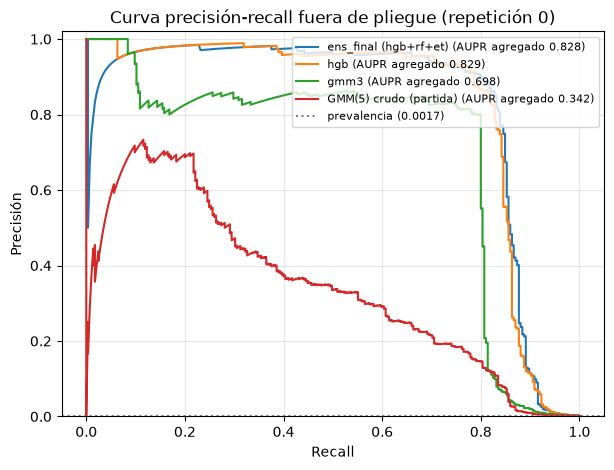

In [17]:
NOMBRE_ENS = "ens_final (hgb+rf+et)"
curvas = {NOMBRE_ENS: OOF[NOMBRE_ENS], "hgb": OOF["hgb"], "gmm3": OOF["gmm3"], "GMM(5) crudo (partida)": oof_base}
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, s in curvas.items():
    prec, rec, _ = precision_recall_curve(y, s)
    ax.plot(rec, prec, label=f"{nombre} (AUPR agregado {aupr(y, s):.3f})")
ax.axhline(y.mean(), ls=":", color="gray", label=f"prevalencia ({y.mean():.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title("Curva precisión-recall fuera de pliegue (repetición 0)")
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### Análisis de errores: subgrupos de fraude

Los fraudes se agrupan en dos subpoblaciones con KMeans (k=2) sobre las primeras `N_VARS_AGRUPACION` (20) variables transformadas y tipificadas, usando solo las filas de fraude. El grupo mayor se llama "fuerte" y el menor "suave". Es una agrupación **descriptiva**: usa las etiquetas para describir el resultado y **no entra en ningún modelo**.

Para cada grupo se mide el recall entre los k scores más altos de cada fold (k = nº de fraudes del fold), con los scores fuera de pliegue del ensemble en la repetición 0, y qué parte del fraude no detectado pertenece al grupo suave.

In [18]:
N_VARS_AGRUPACION = 20  # primeras variables transformadas usadas en el KMeans
SUBGRUPO: dict[str, float] = {}
if int(y.sum()) < 10:
    print("Análisis omitido: menos de 10 fraudes.")
else:
    Z = X[:, :N_VARS_AGRUPACION]
    Zs = (Z - Z.mean(0)) / Z.std(0)
    idx_fraude = np.flatnonzero(y == 1)
    lab = KMeans(2, n_init=10, random_state=SEED).fit_predict(Zs[idx_fraude])
    if (lab == 0).sum() < (lab == 1).sum():
        lab = 1 - lab  # el grupo mayor es "fuerte"
    grupos = {"fuerte": np.zeros(len(y), bool), "suave": np.zeros(len(y), bool)}
    grupos["fuerte"][idx_fraude[lab == 0]] = True
    grupos["suave"][idx_fraude[lab == 1]] = True
    recalls = {g: [] for g in grupos}
    no_detectado = {g: 0 for g in grupos}
    for p in folds0:
        yv, sv = y[p.idx_val], OOF[NOMBRE_ENS][p.idx_val]
        top = np.zeros(len(yv), bool)
        top[np.argsort(-sv, kind="stable")[:int(yv.sum())]] = True
        for g, m in grupos.items():
            recalls[g].append(recall_en_k(yv, sv, m[p.idx_val]))
            no_detectado[g] += int((m[p.idx_val] & ~top).sum())
    total_no_det = sum(no_detectado.values())
    tabla_grupos = pd.DataFrame({
        "fraudes": {g: int(m.sum()) for g, m in grupos.items()},
        "desplazamiento medio |z|": {g: float(np.abs(Zs[m]).mean()) for g, m in grupos.items()},
        "recall@k (media por fold)": {g: float(np.nanmean(r)) for g, r in recalls.items()},
        "no detectados": no_detectado,
    })
    SUBGRUPO = {
        "n_fuerte": int(grupos["fuerte"].sum()), "n_suave": int(grupos["suave"].sum()),
        "recall_fuerte": float(np.nanmean(recalls["fuerte"])), "recall_suave": float(np.nanmean(recalls["suave"])),
        "frac_suave_no_detectado": no_detectado["suave"] / max(total_no_det, 1),
    }
    print(f"Fracción del fraude no detectado que es del grupo suave: {SUBGRUPO['frac_suave_no_detectado']:.2f} ({no_detectado['suave']} de {total_no_det})")
    display(tabla_grupos.round(3))

Fracción del fraude no detectado que es del grupo suave: 0.98 (46 de 47)


,fraudes,desplazamiento medio |z|,recall@k (media por fold),no detectados
fuerte,218,2.056,0.996,1
suave,67,1.186,0.310,46


### Importancia de variables (permutación)

Caída media del AUPR de `hgb` en la partición 0 al permutar cada variable de validación (3 repeticiones, semilla fija). Muestra qué variables sostienen el rendimiento; los nombres de las variables son anónimos.

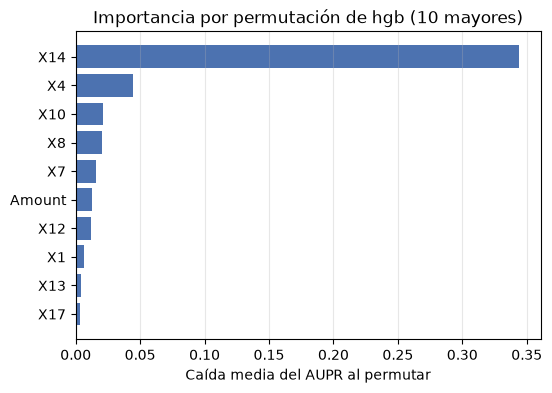

In [19]:
hgb_p0 = GBMSupervisado(SEED).fit(X[p0.idx_fit], y[p0.idx_fit])
imp = importancia_permutacion(hgb_p0, X[p0.idx_val], y[p0.idx_val], n_rep=3, seed=SEED)
top10 = np.argsort(imp)[::-1][:10][::-1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh([COLUMNAS[j] for j in top10], imp[top10], color="#4C72B0")
ax.set_xlabel("Caída media del AUPR al permutar")
ax.set_title("Importancia por permutación de hgb (10 mayores)")
ax.grid(axis="x", alpha=0.3)
plt.show()

## 8. Scoring de producción y CSV

Se ajusta con **todo el fichero de construcción deduplicado** y se puntúa producción en su orden original. El CSV tiene **una columna** `score` (cabecera, sin índice), mayor = más probable fraude.

Nota sobre rangos: la media de rangos se calcula sobre el propio vector de scores de producción. No ajusta ningún parámetro con producción; solo ordena y combina las salidas.

In [20]:
especs_finales = [catalogo_det[n] for n in ENSEMBLE_FINAL]
scores_prod, resultado = entrenar_y_puntuar(especs_finales, df_const, df_prod, OBJETIVO, COL_IMPORTE, SEED, N_JOBS)
escribir_scores(scores_prod, SALIDA_CSV)
for aviso in resultado.avisos:
    print("AVISO:", aviso)
problemas = validar_csv(SALIDA_CSV, len(df_prod))
assert not problemas, problemas
print(f"{SALIDA_CSV}: {len(scores_prod)} filas, 1 columna, válido. Rango [{scores_prod.min():.3f}, {scores_prod.max():.3f}]")
pd.read_csv(SALIDA_CSV).head()

scores.csv: 113923 filas, 1 columna, válido. Rango [0.290, 1.000]


,score
0,0.529288
1,0.440626
2,0.537043
3,0.917808
4,0.473540


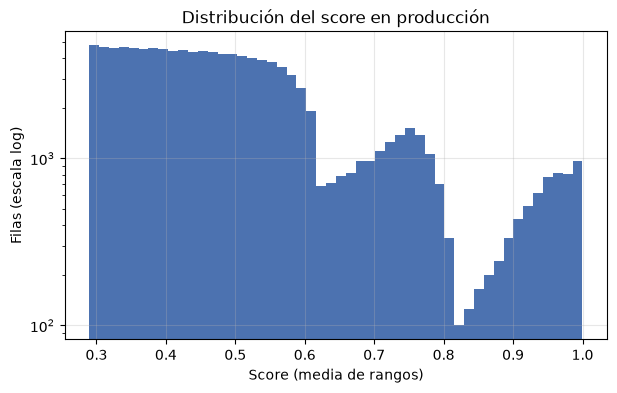

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores_prod, bins=50, color="#4C72B0")
ax.set_yscale("log")
ax.set_xlabel("Score (media de rangos)")
ax.set_ylabel("Filas (escala log)")
ax.set_title("Distribución del score en producción")
ax.grid(alpha=0.3)
plt.show()

## 9. Traza de ejecución

Tabla de la última ejecución: paso, modelo, segundos y nota (incluye reintentos y avisos de degradación).

In [22]:
resultado.traza.tabla()

,paso,modelo,segundos,nota
0,features,-,0.211,
1,detector,hgb,1.259,ok
2,detector,rf,115.902,ok
3,detector,et,74.366,ok
4,ensemble,hgb+rf+et,0.019,media de rangos


### Comprobación de las cifras citadas

Cada cifra citada en el texto se contrasta con el valor calculado en esta ejecución. Si alguna no cuadra, el notebook **avisa y continúa** (las cifras del texto corresponden a la ejecución de referencia con las versiones de `requirements.txt`; otras versiones o sistemas pueden mover los últimos decimales sin que el modelo falle). Con `COMPROBACION_ESTRICTA=true` el notebook se detiene ante cualquier diferencia. En modo demo, o con `SEED` distinto de 42 o `CV_REPETICIONES` distinto de 1, la comprobación se omite (las cifras corresponden a los datos reales con esa configuración).

In [23]:
if USAR_DEMO:
    print("Comprobación omitida en demo (las cifras citadas corresponden a los datos reales).")
elif SEED != 42 or CV_REPETICIONES != 1:
    print(f"Comprobación omitida: las cifras citadas corresponden a SEED=42 y CV_REPETICIONES=1 (actual: SEED={SEED}, CV_REPETICIONES={CV_REPETICIONES}).")
else:
    CIFRAS_CITADAS = {'n_const': (170884, 0), 'n_prod': (113923, 0), 'n_fraudes': (295, 0), 'n_dedup': (166717, 0), 'n_fraudes_dedup': (285, 0), 'deriva_max': (0.02, 0), 'aupr_ens': (0.834, 0.0005), 'aupr_hgb': (0.834, 0.0005), 'aupr_hgb_rf': (0.834, 0.0005), 'aupr_rf': (0.823, 0.0005), 'aupr_et': (0.82, 0.0005), 'aupr_ens_gmm': (0.806, 0.0005), 'aupr_gmm3': (0.706, 0.0005), 'gan_ens_hgb': (0.0006, 5e-05), 'desv_min': (0.055, 0.0005), 'desv_max': (0.069, 0.0005), 'aupr_base_gmm5': (0.375, 0.0005), 'evid_gmm_crudo': (0.75, 0.0005), 'evid_gmm_trans': (0.732, 0.0005), 'evid_hgb_crudo': (0.836, 0.0005), 'evid_hgb_trans': (0.836, 0.0005), 'hgb_defecto': (0.002, 0.0005), 'hgb_reg': (0.836, 0.0005), 'n_fuerte': (218, 0), 'n_suave': (67, 0), 'recall_fuerte': (0.996, 0.0005), 'recall_suave': (0.31, 0.0005), 'frac_suave_no_detectado': (0.979, 0.0005)}  # clave: (valor citado, tolerancia)
    ENS = "ens_final (hgb+rf+et)"
    aupr_cv = tabla_cv["AUPR"]
    desv_cv = tabla_cv.loc[["hgb", "rf", "et", ENS, "hgb+rf", "ens_con_gmm"], "desv_entre_folds"]
    calculado = {
        "n_const": len(df_const_bruto), "n_prod": len(df_prod), "n_fraudes": int(pos),
        "n_dedup": len(df_const), "n_fraudes_dedup": int(df_const[OBJETIVO].sum()),
        "deriva_max": float(dif.max()),
        "aupr_ens": aupr_cv[ENS], "aupr_hgb": aupr_cv["hgb"], "aupr_hgb_rf": aupr_cv["hgb+rf"],
        "aupr_rf": aupr_cv["rf"], "aupr_et": aupr_cv["et"],
        "aupr_ens_gmm": aupr_cv["ens_con_gmm"], "aupr_gmm3": aupr_cv["gmm3"],
        "gan_ens_hgb": aupr_cv[ENS] - aupr_cv["hgb"],
        "desv_min": desv_cv.min(), "desv_max": desv_cv.max(),
        "aupr_base_gmm5": BASE_GMM5,
        "evid_gmm_crudo": evid_features.loc["crudas", "AUPR GMM(3)"], "evid_gmm_trans": evid_features.loc["transformadas", "AUPR GMM(3)"],
        "evid_hgb_crudo": evid_features.loc["crudas", "AUPR HGB"], "evid_hgb_trans": evid_features.loc["transformadas", "AUPR HGB"],
        "hgb_defecto": evid_reg["AUPR"][0], "hgb_reg": evid_reg["AUPR"][1],
        **SUBGRUPO,
    }
    comprobacion = comparar_cifras(CIFRAS_CITADAS, calculado)
    print(comprobacion.to_string(index=False))
    fallan = comprobacion[~comprobacion["ok"]]
    if fallan.empty:
        print("Todas las cifras citadas coinciden con lo calculado.")
    elif COMPROBACION_ESTRICTA:
        raise AssertionError("Hay cifras citadas que no cuadran:" + chr(10) + fallan.to_string(index=False))
    else:
        print(f"AVISO: {len(fallan)} cifra(s) del texto difieren de lo calculado en esta ejecución (normal si las versiones de las librerías o el sistema no son los de requirements.txt). Las que difieren:")
        print(fallan.to_string(index=False))
        print("El modelo y el CSV no se ven afectados. Para detener el notebook ante cualquier diferencia: COMPROBACION_ESTRICTA=true.")

                  cifra      citado    calculado  tolerancia   ok
                n_const 170884.0000 170884.00000     0.00000 True
                 n_prod 113923.0000 113923.00000     0.00000 True
              n_fraudes    295.0000    295.00000     0.00000 True
                n_dedup 166717.0000 166717.00000     0.00000 True
        n_fraudes_dedup    285.0000    285.00000     0.00000 True
             deriva_max      0.0200      0.01587     0.00000 True
               aupr_ens      0.8340      0.83440     0.00050 True
               aupr_hgb      0.8340      0.83380     0.00050 True
            aupr_hgb_rf      0.8340      0.83390     0.00050 True
                aupr_rf      0.8230      0.82320     0.00050 True
                aupr_et      0.8200      0.81980     0.00050 True
           aupr_ens_gmm      0.8060      0.80560     0.00050 True
              aupr_gmm3      0.7060      0.70610     0.00050 True
            gan_ens_hgb      0.0006      0.00060     0.00005 True
          

## 10. Reflexión final

**Resultados.** El enfoque supervisado con árboles regularizados alcanza ~0,834 de AUPR en validación sin fuga (5 folds x 1 repetición), más del doble que el GMM del notebook de partida (0,375, recalculado aquí). Las dos palancas que más pesaron fueron *usar las etiquetas* y *regularizar el boosting*; la transformación de variables no mostró una mejora medible (HGB 0,836 en crudo frente a 0,836 transformado; GMM(3) 0,750 crudo frente a 0,732 transformado en la partición de prueba), de modo que es una decisión de higiene y no una palanca de rendimiento.

**Limitaciones.**
- Pocos positivos: 285 tras deduplicar (~57 por fold). El AUPR por fold varía con desviaciones de 0,055 a 0,069, de modo que distinguir `hgb`, `rf`, `et` y su ensemble es imposible con esta evidencia.
- Los hiperparámetros se eligieron mirando estos mismos folds (exploración en 3 de ellos), por lo que la cifra de validación es algo optimista. No hay un conjunto de test independiente; una validación anidada lo corregiría.
- **Hay un subgrupo de fraude que el modelo apenas detecta.** El análisis de errores de la sección 7 agrupa los fraudes en dos subpoblaciones: un grupo "fuerte" (218 fraudes), muy desplazado en casi todas las variables, y uno "suave" (67 fraudes), con desplazamientos leves. Con los scores fuera de pliegue, el ensemble recupera una fracción 0,996 del grupo fuerte y solo 0,310 del suave, y el grupo suave aporta una fracción 0,979 del fraude no detectado. Es el límite principal del AUPR y no se resuelve con más complejidad de modelo con estas variables.
- Las variables son anónimas: no se pueden construir variables de negocio (frecuencia por cuenta, recencia, comercio) ni validar en el tiempo.

**Riesgos de generalización.** Producción es muy parecida a construcción (diferencia de medias tipificada < 0,02), lo que favorece que la validación sea representativa; si el fraude en producción cambiara de patrón, un modelo supervisado lo detectaría peor que uno de densidad.

**Qué se haría con más tiempo.** Validación anidada y búsqueda de hiperparámetros con intervalos de confianza; más semillas por modelo; calibrar el peso de cada miembro; estudiar los falsos positivos de mayor score; y, solo si la evidencia lo justifica, probar un modelo con interacciones entre variables.